In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
#from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [6]:
dataframe = pd.read_csv("df_corridas.csv")

In [7]:
dataframe['data'] = pd.to_datetime(dataframe['data'], errors='coerce', utc=True)

df_corridas = dataframe[
    (dataframe["data"].dt.year == 2026) & (dataframe["distancia_km"] >= 2.0) & (dataframe["pace_dec"] <8)
].copy()


df_corridas["faixa_distancia"] = pd.cut(
    df_corridas["distancia_km"],
    bins=[2.00, 4.89, 5.4, 5.9, 6.3, 6.9, 7.3, 7.9, 8.3, 9.8, 10.3, 50],
    labels=[
        "2.0_4.89",
        "Base 5K",
        "5-6",
        "Base 6K",
        "6-7",
        "Base 7K",
        "7-8",
        "Base 8K",
        "8-10",
        "Base 10K",
        "+10",
    ],
)

df_corridas["mes"] = df_corridas["data"].dt.to_period("M")

df_corridas["horario"] = df_corridas["data"].dt.strftime("%H:%M")

C:\Users\batat\AppData\Local\Temp\ipykernel_8656\1195286088.py:26: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df_corridas["mes"] = df_corridas["data"].dt.to_period("M")


In [8]:
# Tabela cruzada mostrando sua evolução de volume mês a mês
resumo_mensal = pd.crosstab(df_corridas["mes"], df_corridas["faixa_distancia"], margins=True)
print("--- Evolução de Distância por Mês (2026) ---")
print(resumo_mensal)

--- Evolução de Distância por Mês (2026) ---
faixa_distancia  2.0_4.89  Base 5K  5-6  Base 6K  6-7  Base 7K  7-8  Base 8K  \
mes                                                                            
2026-01                 3        2    1        0    0        0    0        0   
2026-02                 1        0    1        0    0        0    0        0   
2026-03                 3        6    0        0    0        0    0        0   
2026-04                 3        8    0        1    0        2    0        2   
2026-05                 0        8    0        2    0        6    0        3   
2026-06                 1        9    0        2    0        3    2        1   
2026-07                 1        2    0        5    1        3    0        2   
2026-08                 0        3    0        6    0        5    0        2   
2026-09                 4        1    0        1    1        6    1        0   
2026-10                 3        0    0        2    0        2    0        

In [9]:
df5km = df_corridas[df_corridas['faixa_distancia'] == 'Base 5K'].copy()

df5km = df5km.sort_values(by="pace_dec", ascending=True)



display(df5km.head())

,record_id,data,modalidade,distancia_km,duracao_min,duracao_fmt,pace_dec,pace_fmt,bpm_min,bpm_medio,...,altitude_max_m,ganho_elev_total_m,perda_elev_total_m,kcal,te_aerobico,te_anaerobico,tem_splits_oficiais,faixa_distancia,mes,horario
208,vrh+DwAAAAACAAAAYASkc6ABAAA=,2026-09-05 19:15:24.000+00:00,Rua,5.38,24.62,24:37,4.58,4:35,140.0,185,...,6.264000e+02,49.3,-51.8,369.0,3.0,4.5,True,Base 5K,2026-09,19:15
191,vrh+DwAAAAACAAAASA0M6Z8BAAA=,2026-08-09 21:21:49.000+00:00,Rua,5.00,23.63,23:38,4.73,4:44,84.0,167,...,6.210000e+02,29.3,-34.4,319.0,2.8,2.3,True,Base 5K,2026-08,21:21
171,vrh+DwAAAAACAAAAgB93OZ8BAAA=,2026-07-06 19:05:36.000+00:00,Rua,5.01,24.27,24:16,4.84,4:51,79.0,177,...,6.217000e+02,28.6,-31.8,328.0,2.9,3.8,True,Base 5K,2026-07,19:05
115,bFAkEgAAAAACAAAAfhfQdp0BAAA=,2026-04-10 06:54:02.238+00:00,Rua,4.90,25.24,25:15,5.15,5:09,96.0,134,...,1.400000e-45,0.0,0.0,435.0,1.4,0.0,True,Base 5K,2026-04,06:54
153,vrh+DwAAAAACAAAAoKliqZ4BAAA=,2026-06-08 19:37:56.000+00:00,Rua,5.00,26.15,26:09,5.23,5:14,79.0,163,...,6.235000e+02,77.4,-93.6,321.0,2.7,1.8,True,Base 5K,2026-06,19:37


In [ ]:
df5km.columns

Index(['record_id', 'data', 'modalidade', 'distancia_km', 'duracao_min',
       'duracao_fmt', 'pace_dec', 'pace_fmt', 'bpm_min', 'bpm_medio',
       'bpm_max', 'deriva_cardiaca', 'pct_tempo_bpm_165+', 'cadencia_min',
       'cadencia_media', 'cadencia_max', 'altitude_min_m', 'altitude_media_m',
       'altitude_max_m', 'ganho_elev_total_m', 'perda_elev_total_m', 'kcal',
       'te_aerobico', 'te_anaerobico', 'tem_splits_oficiais',
       'faixa_distancia', 'horario'],
      dtype='str')

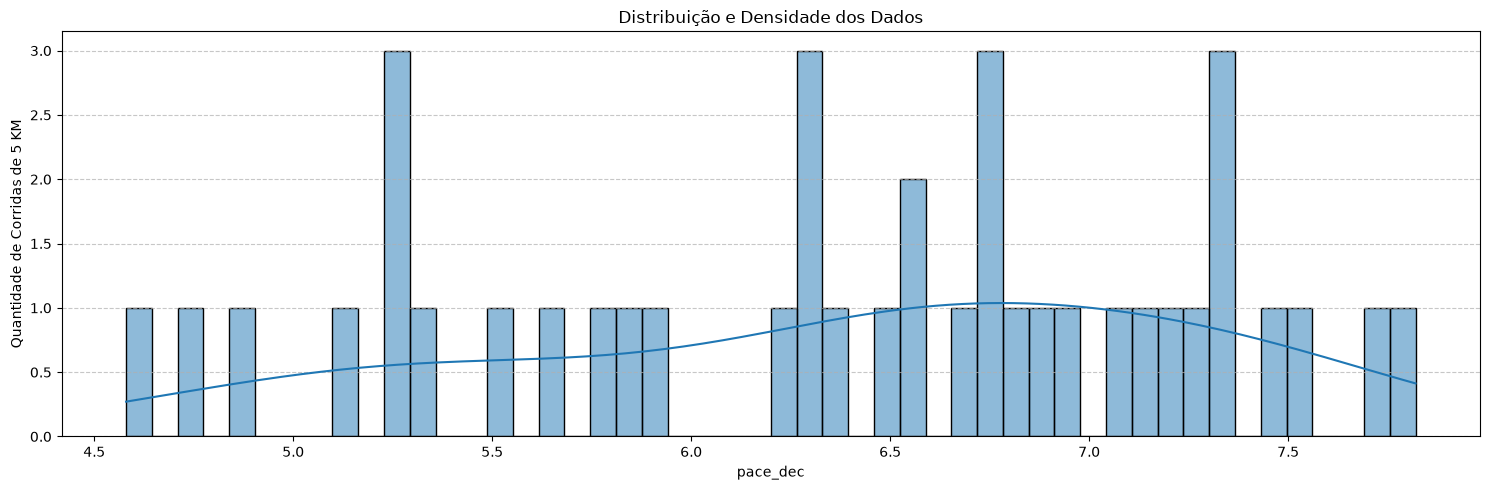

In [ ]:
plt.figure(figsize=(15, 5))
sns.histplot(df5km['pace_dec'], kde=True, color='#1f77b4', bins=50)
plt.title("Distribuição e Densidade dos Dados")
plt.ylabel("Quantidade de Corridas de 5 KM")
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

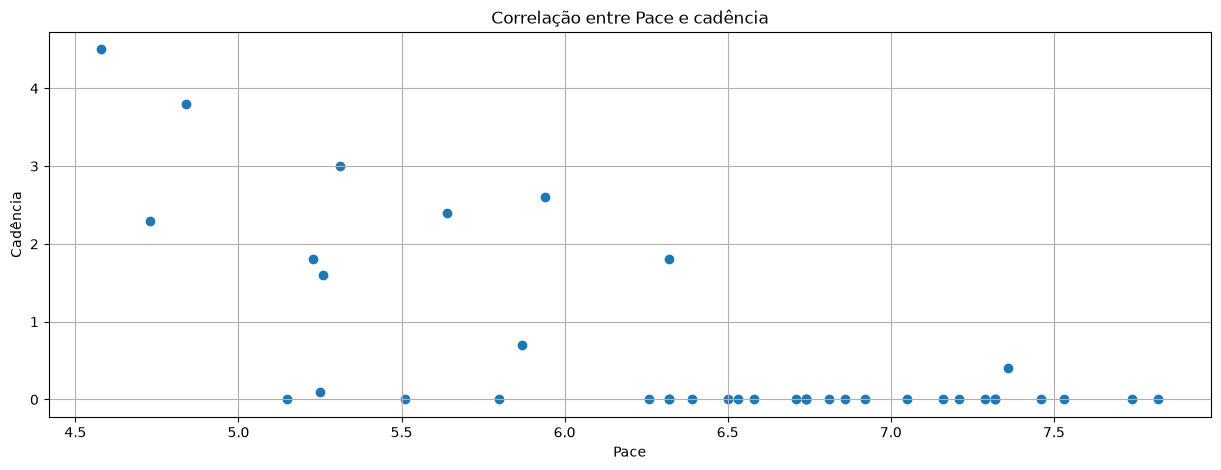

In [ ]:
plt.figure(figsize=(15, 5))

plt.xlabel('Pace')
plt.ylabel('Cadência')
plt.title('Correlação entre Pace e cadência')
plt.scatter(df5km['pace_dec'], df5km['te_anaerobico'])
plt.grid(True)
plt.show()

In [10]:
display(df5km.head())

,record_id,data,modalidade,distancia_km,duracao_min,duracao_fmt,pace_dec,pace_fmt,bpm_min,bpm_medio,...,altitude_max_m,ganho_elev_total_m,perda_elev_total_m,kcal,te_aerobico,te_anaerobico,tem_splits_oficiais,faixa_distancia,mes,horario
208,vrh+DwAAAAACAAAAYASkc6ABAAA=,2026-09-05 19:15:24.000+00:00,Rua,5.38,24.62,24:37,4.58,4:35,140.0,185,...,6.264000e+02,49.3,-51.8,369.0,3.0,4.5,True,Base 5K,2026-09,19:15
191,vrh+DwAAAAACAAAASA0M6Z8BAAA=,2026-08-09 21:21:49.000+00:00,Rua,5.00,23.63,23:38,4.73,4:44,84.0,167,...,6.210000e+02,29.3,-34.4,319.0,2.8,2.3,True,Base 5K,2026-08,21:21
171,vrh+DwAAAAACAAAAgB93OZ8BAAA=,2026-07-06 19:05:36.000+00:00,Rua,5.01,24.27,24:16,4.84,4:51,79.0,177,...,6.217000e+02,28.6,-31.8,328.0,2.9,3.8,True,Base 5K,2026-07,19:05
115,bFAkEgAAAAACAAAAfhfQdp0BAAA=,2026-04-10 06:54:02.238+00:00,Rua,4.90,25.24,25:15,5.15,5:09,96.0,134,...,1.400000e-45,0.0,0.0,435.0,1.4,0.0,True,Base 5K,2026-04,06:54
153,vrh+DwAAAAACAAAAoKliqZ4BAAA=,2026-06-08 19:37:56.000+00:00,Rua,5.00,26.15,26:09,5.23,5:14,79.0,163,...,6.235000e+02,77.4,-93.6,321.0,2.7,1.8,True,Base 5K,2026-06,19:37


Parciais analisadas em 2026: 781
Custo médio a cada +1% de inclinação: +6.1 seg/km no pace | +1.2 bpm no coração


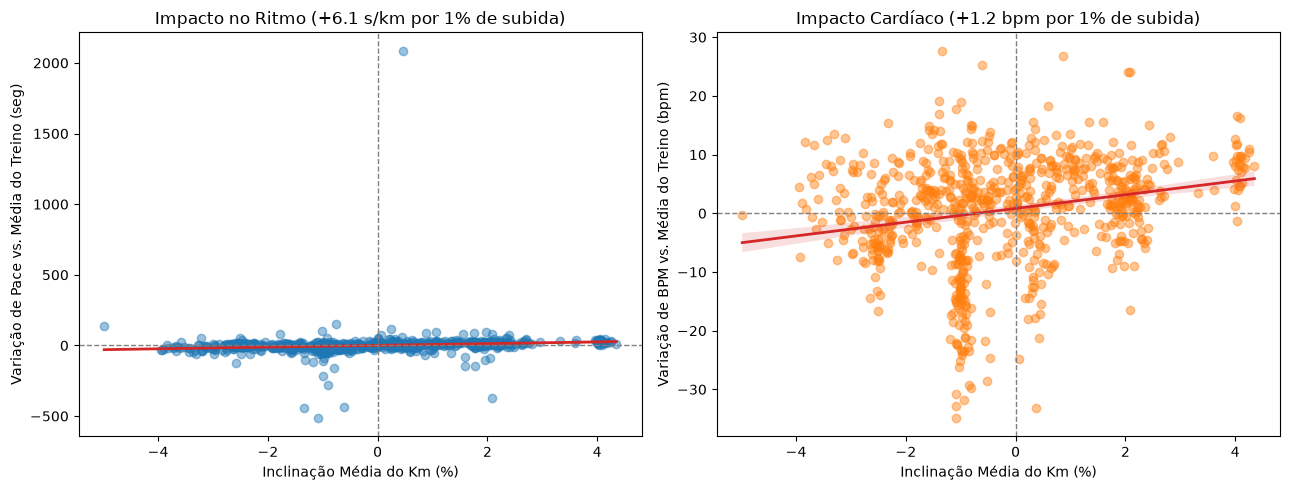

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df_corridas = pd.read_csv("df_corridas.csv", parse_dates=["data"])
df_por_km = pd.read_csv("df_por_km.csv", parse_dates=["data"])

# Filtra treinos válidos de rua em 2026 (>= 2 km no total e parciais cheias >= 850 m)
ids_2026 = df_corridas[
    (df_corridas["data"].dt.year == 2026)
    & (df_corridas["modalidade"] == "Rua")
    & (df_corridas["distancia_km"] >= 2.0)
]["record_id"]

df_subidas = df_por_km[
    (df_por_km["record_id"].isin(ids_2026))
    & (df_por_km["distancia_m"] >= 850)
    & (df_por_km["inclinacao_pct"].between(-6, 6))
].dropna(subset=["inclinacao_pct", "delta_pace_seg", "delta_bpm"])

# Calcula a inclinação (coeficiente angular) do impacto por +1% de aclive
coef_pace = np.polyfit(df_subidas["inclinacao_pct"], df_subidas["delta_pace_seg"], 1)[0]
coef_bpm = np.polyfit(df_subidas["inclinacao_pct"], df_subidas["delta_bpm"], 1)[0]

print(f"Parciais analisadas em 2026: {len(df_subidas)}")
print(f"Custo médio a cada +1% de inclinação: +{coef_pace:.1f} seg/km no pace | +{coef_bpm:.1f} bpm no coração")

# Visualização lado a lado: Inclinação vs. Perda de Ritmo e Salto de BPM
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    data=df_subidas,
    x="inclinacao_pct",
    y="delta_pace_seg",
    ax=axes[0],
    scatter_kws={"alpha": 0.45, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2},
)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title(f"Impacto no Ritmo (+{coef_pace:.1f} s/km por 1% de subida)")
axes[0].set_xlabel("Inclinação Média do Km (%)")
axes[0].set_ylabel("Variação de Pace vs. Média do Treino (seg)")

sns.regplot(
    data=df_subidas,
    x="inclinacao_pct",
    y="delta_bpm",
    ax=axes[1],
    scatter_kws={"alpha": 0.45, "color": "#ff7f0e"},
    line_kws={"color": "#d62728", "linewidth": 2},
)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title(f"Impacto Cardíaco (+{coef_bpm:.1f} bpm por 1% de subida)")
axes[1].set_xlabel("Inclinação Média do Km (%)")
axes[1].set_ylabel("Variação de BPM vs. Média do Treino (bpm)")

plt.tight_layout()
plt.show()

=== TOP 10 QUILÔMETROS MAIS ÍNGREMES (2026) ===
               data  km  saldo_elev_m  ganho_elev_m  inclinacao_pct pace_fmt  delta_pace_seg  bpm_medio  delta_bpm
2026-05-19 19:02:49   4          43.5          43.5            4.35     7:07             7.3      151.0        8.0
2026-08-12 18:53:03   4          42.6          42.6            4.26     6:40            33.7      159.4       10.4
2026-07-16 19:22:22   4          42.5          43.3            4.25     6:24            24.6      158.9       10.9
2026-09-17 19:22:57   4          41.8          43.2            4.18     6:15            23.7      168.4        9.4
2026-10-13 20:00:00   3          41.8          43.1            4.18     7:00            15.9      151.8        7.8
2026-08-14 20:10:15   4          41.4          43.1            4.14     6:56            43.8      147.9        7.9
2026-07-13 19:30:06   4          41.3          42.5            4.13     5:40            18.5      155.2        5.2
2026-07-01 19:57:06   4         

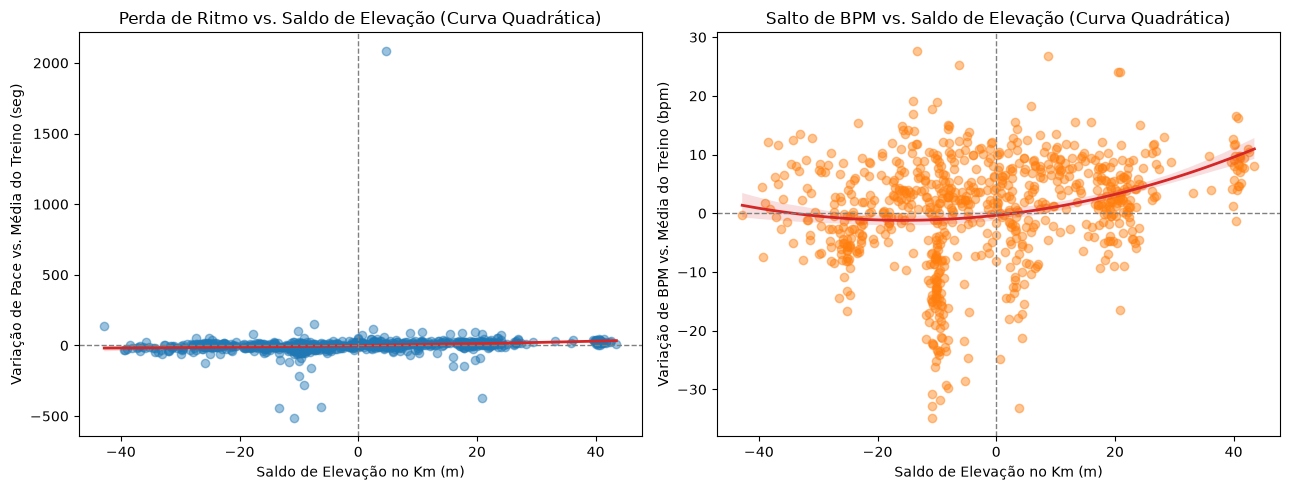

In [3]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df_corridas = pd.read_csv("df_corridas.csv", parse_dates=["data"])
df_por_km = pd.read_csv("df_por_km.csv", parse_dates=["data"])

ids_2026 = df_corridas[
    (df_corridas["data"].dt.year == 2026)
    & (df_corridas["modalidade"] == "Rua")
    & (df_corridas["distancia_km"] >= 2.0)
]["record_id"]

# Amplia o limite físico para +-180 m/km (18% de inclinação média) para não cortar subidas reais
df_m = df_por_km[
    (df_por_km["record_id"].isin(ids_2026))
    & (df_por_km["distancia_m"] >= 850)
    & (df_por_km["saldo_elev_m"].between(-180, 180))
].dropna(subset=["saldo_elev_m", "ganho_elev_m", "delta_pace_seg", "delta_bpm"]).copy()

# 1. Auditoria: mostra as 10 subidas mais pesadas do seu ano para conferir se são todas reais
print("=== TOP 10 QUILÔMETROS MAIS ÍNGREMES (2026) ===")
print(
    df_m.nlargest(10, "saldo_elev_m")[[
        "data",
        "km",
        "saldo_elev_m",
        "ganho_elev_m",
        "inclinacao_pct",
        "pace_fmt",
        "delta_pace_seg",
        "bpm_medio",
        "delta_bpm",
    ]].to_string(index=False)
)

# 2. Recalcula o custo por metro com as subidas fortes incluídas
pace_por_m_saldo = np.polyfit(df_m["saldo_elev_m"], df_m["delta_pace_seg"], 1)[0]
bpm_por_m_saldo = np.polyfit(df_m["saldo_elev_m"], df_m["delta_bpm"], 1)[0]

pace_por_m_ganho = np.polyfit(df_m["ganho_elev_m"], df_m["delta_pace_seg"], 1)[0]
bpm_por_m_ganho = np.polyfit(df_m["ganho_elev_m"], df_m["delta_bpm"], 1)[0]

print("\n=== CUSTO REAL POR METRO (COM SUBIDAS PESADAS) ===")
print(f"Saldo líquido (+1 m): +{pace_por_m_saldo:.2f} seg/km | +{bpm_por_m_saldo:.2f} bpm")
print(f"Ganho bruto   (+1 m): +{pace_por_m_ganho:.2f} seg/km | +{bpm_por_m_ganho:.2f} bpm")

# 3. Plota com ajuste polinomial (order=2) para enxergar onde a curva empina de vez
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    data=df_m,
    x="saldo_elev_m",
    y="delta_pace_seg",
    order=2,
    ax=axes[0],
    scatter_kws={"alpha": 0.45, "color": "#1f77b4"},
    line_kws={"color": "#d62728", "linewidth": 2},
)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title("Perda de Ritmo vs. Saldo de Elevação (Curva Quadrática)")
axes[0].set_xlabel("Saldo de Elevação no Km (m)")
axes[0].set_ylabel("Variação de Pace vs. Média do Treino (seg)")

sns.regplot(
    data=df_m,
    x="saldo_elev_m",
    y="delta_bpm",
    order=2,
    ax=axes[1],
    scatter_kws={"alpha": 0.45, "color": "#ff7f0e"},
    line_kws={"color": "#d62728", "linewidth": 2},
)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title("Salto de BPM vs. Saldo de Elevação (Curva Quadrática)")
axes[1].set_xlabel("Saldo de Elevação no Km (m)")
axes[1].set_ylabel("Variação de BPM vs. Média do Treino (bpm)")

plt.tight_layout()
plt.show()

Trechos de 100m analisados (2026): 7645
=== CUSTO POR +1 METRO SUBIDO EM 100M (= +1% INCLINAÇÃO) ===
Efeito imediato : +4.56 seg/km no pace | +0.62 bpm no coração
Efeito 100m após: +0.96 bpm no coração (inércia cardíaca)

Na sua rampa do Km 1 (+4,6 m em 100 m): custo estimado de +21 seg/km


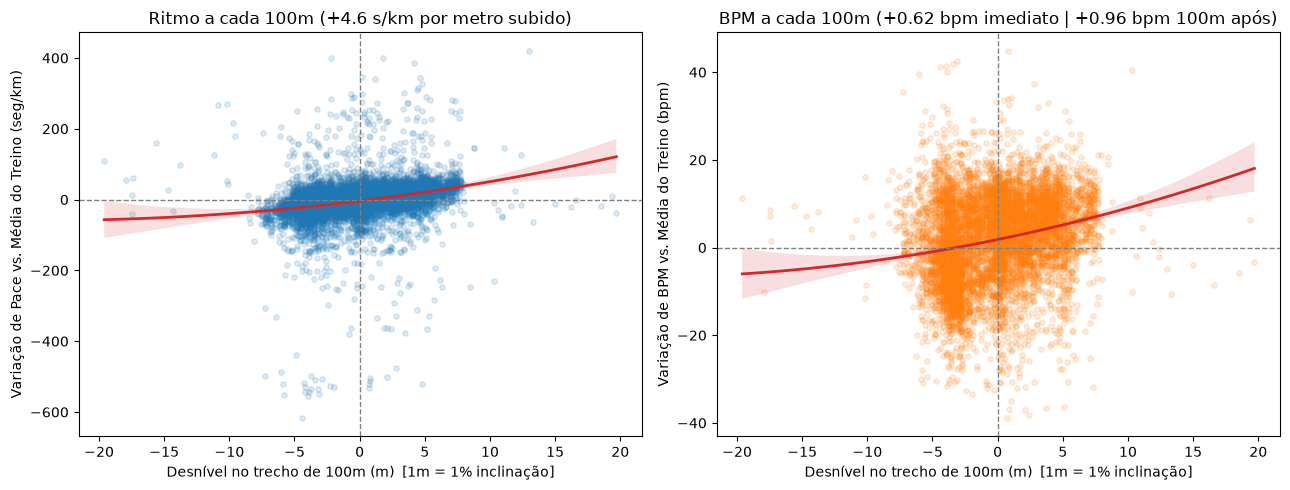

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df_corridas = pd.read_csv("df_corridas.csv", parse_dates=["data"])
df_por_100m = pd.read_csv("df_por_100m.csv", parse_dates=["data"])

# Filtra treinos válidos de rua em 2026 (>= 2 km no total)
ids_2026 = df_corridas[
    (df_corridas["data"].dt.year == 2026)
    & (df_corridas["modalidade"] == "Rua")
    & (df_corridas["distancia_km"] >= 2.0)
]["record_id"]

# Filtra fatias cheias (>= 90m), pula os primeiros 200m (largada) e limita relevo a +-20m/100m
df_100 = df_por_100m[
    (df_por_100m["record_id"].isin(ids_2026))
    & (df_por_100m["distancia_m"] >= 90)
    & (df_por_100m["trecho_100m"] > 2)
    & (df_por_100m["saldo_elev_m"].between(-20, 20))
].dropna(subset=["saldo_elev_m", "delta_pace_seg_km", "delta_bpm"]).copy()

# 1. Custo imediato por +1 metro subido em 100m (equivale a +1% de inclinação)
pace_por_m_100 = np.polyfit(df_100["saldo_elev_m"], df_100["delta_pace_seg_km"], 1)[0]
bpm_por_m_100 = np.polyfit(df_100["saldo_elev_m"], df_100["delta_bpm"], 1)[0]

# 2. Custo cardíaco com atraso de 100m (inclinacao_lag1_pct)
df_lag = df_100.dropna(subset=["inclinacao_lag1_pct"])
bpm_lag1 = np.polyfit(df_lag["inclinacao_lag1_pct"], df_lag["delta_bpm"], 1)[0]

print(f"Trechos de 100m analisados (2026): {len(df_100)}")
print("=== CUSTO POR +1 METRO SUBIDO EM 100M (= +1% INCLINAÇÃO) ===")
print(f"Efeito imediato : +{pace_por_m_100:.2f} seg/km no pace | +{bpm_por_m_100:.2f} bpm no coração")
print(f"Efeito 100m após: +{bpm_lag1:.2f} bpm no coração (inércia cardíaca)")
print(f"\nNa sua rampa do Km 1 (+4,6 m em 100 m): custo estimado de +{pace_por_m_100 * 4.6:.0f} seg/km")

# 3. Gráficos na escala de 100m (com curva quadrática order=2)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.regplot(
    data=df_100,
    x="saldo_elev_m",
    y="delta_pace_seg_km",
    order=2,
    ax=axes[0],
    scatter_kws={"alpha": 0.15, "color": "#1f77b4", "s": 15},
    line_kws={"color": "#d62728", "linewidth": 2},
)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set_title(f"Ritmo a cada 100m (+{pace_por_m_100:.1f} s/km por metro subido)")
axes[0].set_xlabel("Desnível no trecho de 100m (m)  [1m = 1% inclinação]")
axes[0].set_ylabel("Variação de Pace vs. Média do Treino (seg/km)")

sns.regplot(
    data=df_100,
    x="saldo_elev_m",
    y="delta_bpm",
    order=2,
    ax=axes[1],
    scatter_kws={"alpha": 0.15, "color": "#ff7f0e", "s": 15},
    line_kws={"color": "#d62728", "linewidth": 2},
)
axes[1].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[1].axvline(0, color="gray", linestyle="--", linewidth=1)
axes[1].set_title(f"BPM a cada 100m (+{bpm_por_m_100:.2f} bpm imediato | +{bpm_lag1:.2f} bpm 100m após)")
axes[1].set_xlabel("Desnível no trecho de 100m (m)  [1m = 1% inclinação]")
axes[1].set_ylabel("Variação de BPM vs. Média do Treino (bpm)")

plt.tight_layout()
plt.show()

In [12]:
import pandas as pd

df_corridas = pd.read_csv("df_corridas.csv", parse_dates=["data"])
df_por_100m = pd.read_csv("df_por_100m.csv", parse_dates=["data"])

ids_2026 = df_corridas[
    (df_corridas["data"].dt.year == 2026)
    & (df_corridas["modalidade"] == "Rua")
    & (df_corridas["distancia_km"] >= 2.0)
]["record_id"]

df_check = df_por_100m[
    (df_por_100m["record_id"].isin(ids_2026))
    & (df_por_100m["distancia_m"] >= 90)
].dropna(subset=["saldo_elev_m"])

acima_20 = df_check[df_check["saldo_elev_m"].abs() > 20]
print(f"Total de trechos de 100m em 2026: {len(df_check)}")
print(f"Trechos que passam de +-20m: {len(acima_20)}")

print("\n=== TOP 10 MAIORES SUBIDAS EM 100M (2026) ===")
print(
    df_check.nlargest(10, "saldo_elev_m")[[
        "data",
        "km_ref",
        "dist_acum_m",
        "saldo_elev_m",
        "inclinacao_pct",
        "pace_fmt",
        "bpm_medio",
    ]].to_string(index=False)
)

Total de trechos de 100m em 2026: 7923
Trechos que passam de +-20m: 12

=== TOP 10 MAIORES SUBIDAS EM 100M (2026) ===
                   data  km_ref  dist_acum_m  saldo_elev_m  inclinacao_pct pace_fmt  bpm_medio
2026-05-25 19:20:03.000       7       7000.0          42.5           42.47     6:56      140.9
    2026-06-17 19:29:14      10       9200.0          32.2           32.17     4:59      176.0
    2026-10-15 20:05:15       7       6800.0          22.2           22.17     6:12      149.5
2026-05-27 19:41:22.000       8       7300.0          21.9           21.92     6:51      141.1
    2026-09-17 19:22:57       7       6200.0          19.7           19.68     5:14      155.6
2026-05-20 18:46:04.000       6       6000.0          19.4           19.42     6:43      149.4
    2026-08-19 20:00:23       7       6800.0          18.5           18.52     6:01      138.1
2026-05-12 19:46:30.000       5       4100.0          16.6           16.61     6:44      137.4
2026-05-04 18:38:17.000    